# TXON Data Science Internship - Task 01
## Data Cleaning & Basic Visualization
**Dataset:** Sample Superstore (Retail Sales)  
**Tech Stack:** Python, Pandas, Matplotlib, Seaborn

Isi notebook:
1. Load data & inspeksi struktur (`head()`, `info()`, `describe()`)
2. Data cleaning (missing values, duplikat, tipe data)
3. Statistik dasar (Mean, Median, Mode, Std)
4. Visualisasi (Bar Chart, Histogram, Pie Chart)
5. Kesimpulan

## 1. Import Library

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## 2. Load Data & Inspeksi Struktur
File ini memakai encoding `cp1252`, jadi harus dituliskan saat `read_csv`.

In [3]:
# Pastikan file 'Superstore.csv' ada di folder yang sama dengan notebook ini
df = pd.read_csv("Superstore.csv", encoding="cp1252")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
print("Jumlah baris & kolom:", df.shape)
df.info()

Jumlah baris & kolom: (9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null  

In [5]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 3. Data Cleaning

### 3.1 Missing Values

In [6]:
print(df.isnull().sum())
print("\nTotal missing value:", df.isnull().sum().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total missing value: 0


In [7]:
# Jika ada missing value: angka diisi median, teks diisi modus.
# (Pada dataset ini tidak ada, jadi tidak ada baris yang berubah.)
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype in ["int64", "float64"]:
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])
print("Sisa missing value:", df.isnull().sum().sum())

Sisa missing value: 0


### 3.2 Duplikat

In [8]:
print("Duplikat sebelum:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplikat sesudah:", df.duplicated().sum())
print("Jumlah baris sekarang:", len(df))

Duplikat sebelum: 0
Duplikat sesudah: 0
Jumlah baris sekarang: 9994


### 3.3 Perbaikan Tipe Data
`Order Date` dan `Ship Date` masih bertipe string, jadi diubah menjadi datetime.

In [9]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# Kolom tambahan untuk analisis
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month

df[["Order Date", "Ship Date", "Order Year", "Order Month"]].dtypes

Order Date     datetime64[us]
Ship Date      datetime64[us]
Order Year              int32
Order Month             int32
dtype: object

## 4. Statistik Dasar
Mean, Median, Mode, dan Standard Deviation untuk kolom numerik utama.

In [10]:
num_cols = ["Sales", "Quantity", "Discount", "Profit"]

stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std Dev": df[num_cols].std(),
}).round(2)
stats

,Mean,Median,Mode,Std Dev
Sales,229.86,54.49,12.96,623.25
Quantity,3.79,3.00,3.00,2.23
Discount,0.16,0.20,0.00,0.21
Profit,28.66,8.67,0.00,234.26


**Catatan:** Mean `Sales` jauh lebih besar dari median, artinya distribusinya miring ke kanan
(sedikit transaksi bernilai sangat besar). `Profit` juga punya nilai negatif, tanda ada transaksi yang rugi.

## 5. Visualisasi

### 5.1 Bar Chart - Total Sales per Category

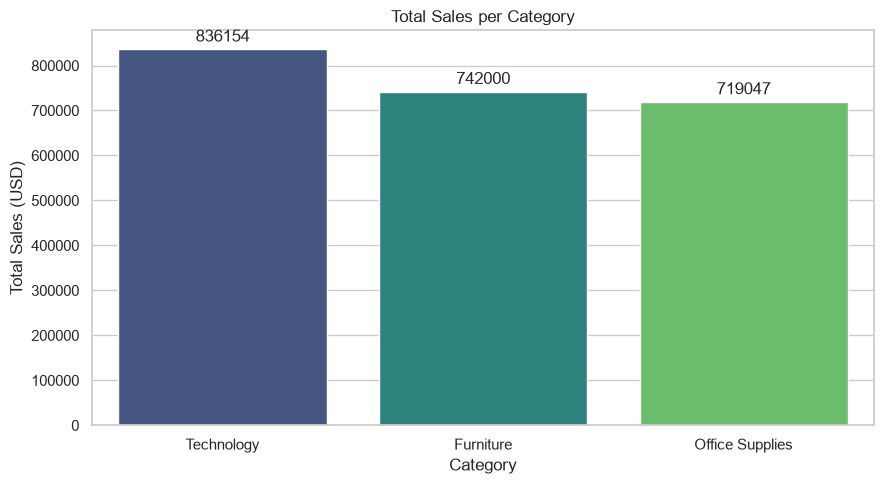

In [11]:
cat_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False).reset_index()

ax = sns.barplot(data=cat_sales, x="Category", y="Sales", hue="Category", palette="viridis", legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", padding=3)
plt.title("Total Sales per Category")
plt.ylabel("Total Sales (USD)")
plt.tight_layout()
plt.show()

### 5.2 Bar Chart - Total Profit per Sub-Category

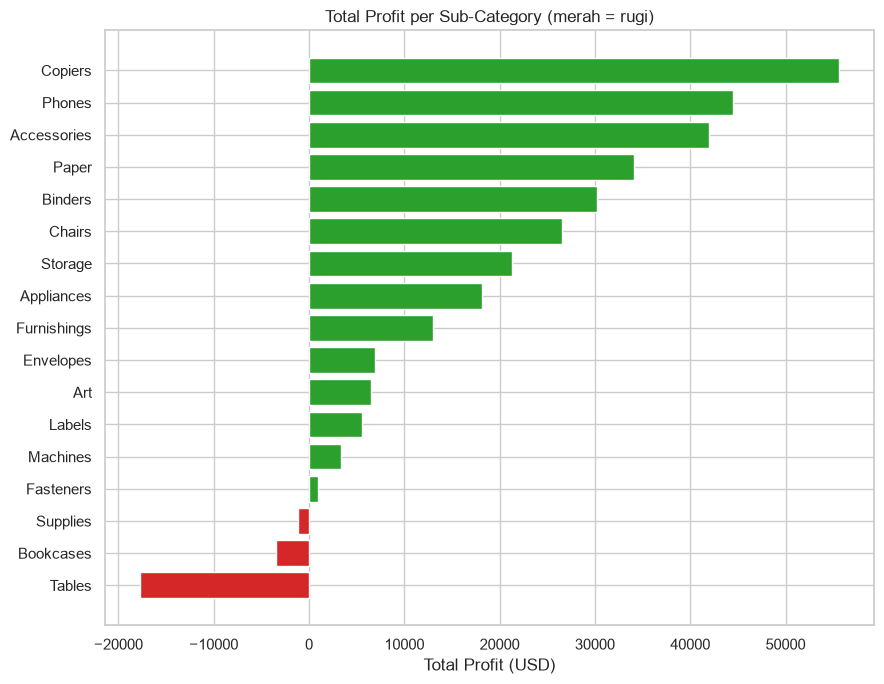

In [12]:
sub_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values().reset_index()

plt.figure(figsize=(9, 7))
colors = ["#d62728" if v < 0 else "#2ca02c" for v in sub_profit["Profit"]]
plt.barh(sub_profit["Sub-Category"], sub_profit["Profit"], color=colors)
plt.title("Total Profit per Sub-Category (merah = rugi)")
plt.xlabel("Total Profit (USD)")
plt.tight_layout()
plt.show()

### 5.3 Histogram - Distribusi Sales dan Profit

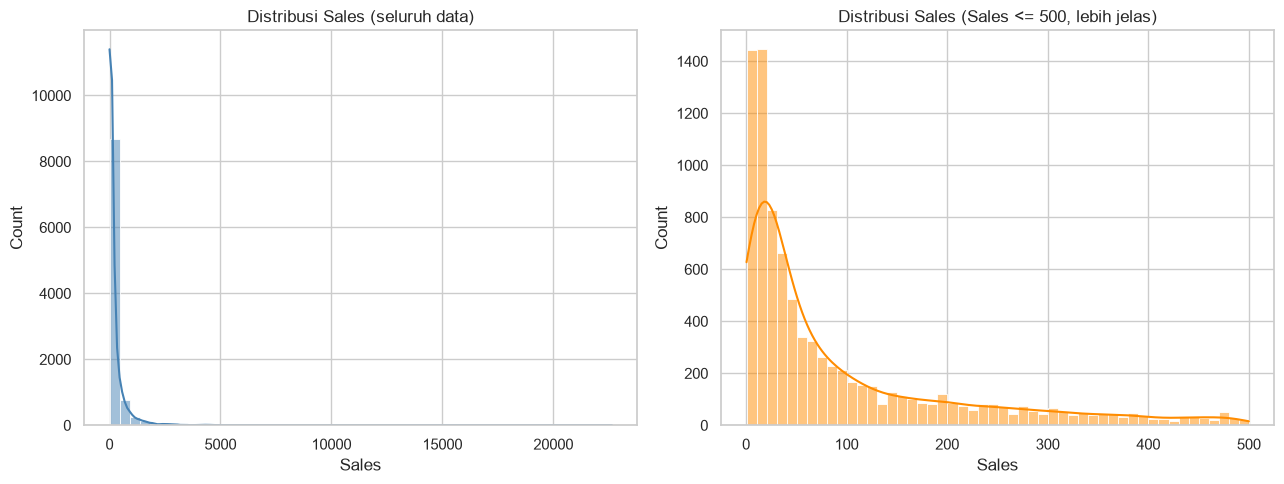

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["Sales"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Sales (seluruh data)")

sns.histplot(df[df["Sales"] <= 500]["Sales"], bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Distribusi Sales (Sales <= 500, lebih jelas)")

plt.tight_layout()
plt.show()

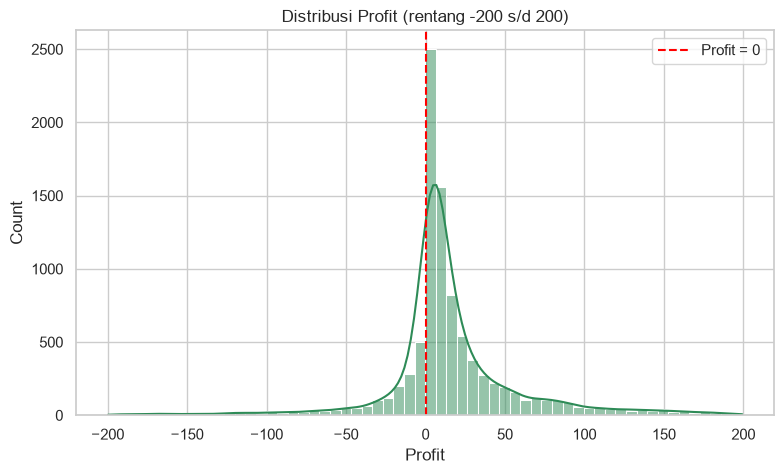

In [14]:
plt.figure(figsize=(9, 5))
sns.histplot(df[df["Profit"].between(-200, 200)]["Profit"], bins=60, kde=True, color="seagreen")
plt.axvline(0, color="red", linestyle="--", label="Profit = 0")
plt.title("Distribusi Profit (rentang -200 s/d 200)")
plt.legend()
plt.show()

### 5.4 Pie Chart - Proporsi Sales per Segment

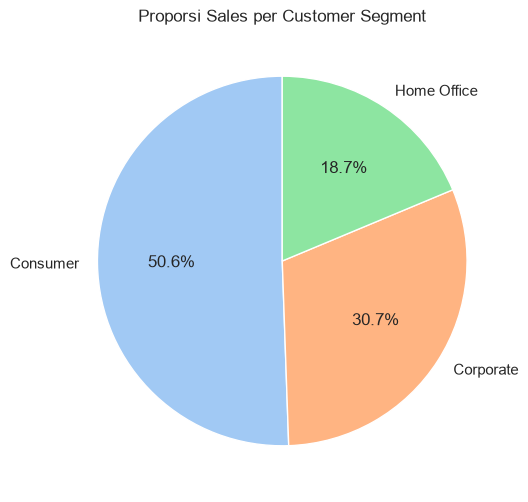

In [15]:
seg_sales = df.groupby("Segment")["Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(seg_sales, labels=seg_sales.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("pastel"), wedgeprops={"edgecolor": "white"})
plt.title("Proporsi Sales per Customer Segment")
plt.show()

### 5.5 Pie Chart - Proporsi Sales per Region

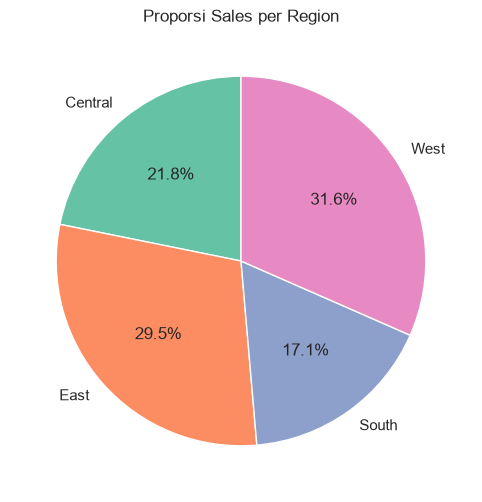

In [16]:
reg_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(reg_sales, labels=reg_sales.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("Set2"), wedgeprops={"edgecolor": "white"})
plt.title("Proporsi Sales per Region")
plt.show()

### 5.6 Bonus - Tren Sales per Tahun

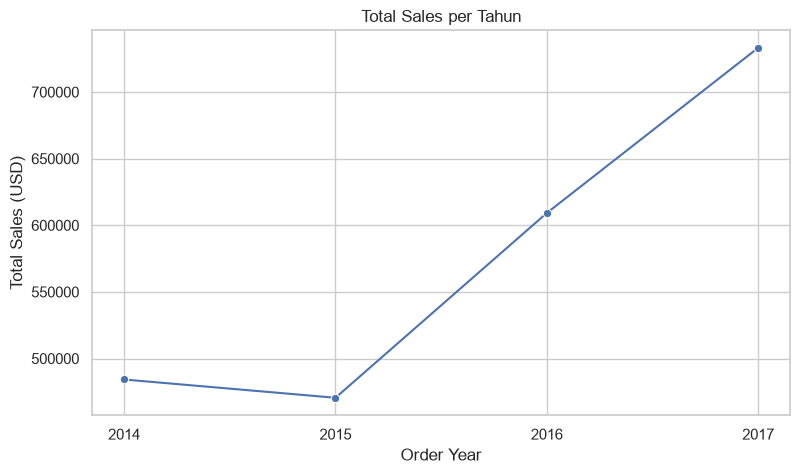

In [17]:
yearly = df.groupby("Order Year")["Sales"].sum().reset_index()

sns.lineplot(data=yearly, x="Order Year", y="Sales", marker="o")
plt.xticks(yearly["Order Year"])
plt.title("Total Sales per Tahun")
plt.ylabel("Total Sales (USD)")
plt.show()

## 6. Kesimpulan

In [18]:
print("Kategori dengan Sales tertinggi :", cat_sales.iloc[0]["Category"])
print("Region dengan Sales tertinggi   :", reg_sales.idxmax())
print("Segment dengan Sales tertinggi  :", seg_sales.idxmax())
print("Sub-Category paling rugi        :", sub_profit.iloc[0]["Sub-Category"])
print("Sub-Category paling untung      :", sub_profit.iloc[-1]["Sub-Category"])

Kategori dengan Sales tertinggi : Technology
Region dengan Sales tertinggi   : West
Segment dengan Sales tertinggi  : Consumer
Sub-Category paling rugi        : Tables
Sub-Category paling untung      : Copiers
